# 04 - Statistical Analysis (Phase 3)
**Goal:** formally test and quantify the relationships found in the EDA (notebook 03). No machine-learning models are trained.

**Data (only):** `data/processed/modeling_dataset.csv` (9,912 distinct feature profiles) and, for the policy replication in section 11,
`train.csv` / `validation.csv` / `test.csv`. The modelling dataset is not modified (a SHA-256 check at start and end enforces this).

**Conventions used throughout**
- alpha = 0.05, two-sided tests; "significant" always refers to the *adjusted* p-value when a family of tests exists.
- Every test lists its research question, H0/H1, why it fits, the statistic, p-value, effect size and a 95% CI where meaningful.
- **Statistical vs practical significance:** with n of about 10,000, even trivial differences give tiny p-values. Effect sizes and confidence intervals, not p-values, convey importance.
- **A small p-value does not make a feature a good predictor**, and a large effect is not evidence of causation. All results are associations in observational data.

In [1]:
import warnings
warnings.simplefilter("always")           # surface every warning (the notebook is expected to produce none)
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"
OUT = ROOT / "results" / "metrics" / "statistical"
FIGDIR = ROOT / "results" / "figures" / "statistical"
OUT.mkdir(parents=True, exist_ok=True); FIGDIR.mkdir(parents=True, exist_ok=True)

ALPHA, SEED, B_BOOT = 0.05, 42, 2000
PLACED_C, NOT_C, NEUTRAL = "#2166ac", "#e08214", "#6b7785"
sns.set_theme(style="whitegrid", rc={"grid.color": "#e3e6ea", "axes.edgecolor": "#9aa3ad", "axes.titlesize": 12,
                                      "axes.titleweight": "semibold", "axes.labelsize": 10.5, "figure.dpi": 110})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 120)

TARGET = "PlacementStatus"
CONT = ["CGPA", "AptitudeTestScore", "SoftSkillsRating", "SSC_Marks", "HSC_Marks"]
COUNT = ["Internships", "Projects", "Workshops/Certifications"]
NUM = CONT + COUNT
CATB = ["ExtracurricularActivities", "PlacementTraining"]
FEATURES = NUM + CATB

sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
MODEL_SHA_START = sha(PROC / "modeling_dataset.csv")

df = pd.read_csv(PROC / "modeling_dataset.csv")
splits = {s: pd.read_csv(PROC / f"{s}.csv") for s in ["train", "validation", "test"]}
assert df.shape == (9912, 11) and df.isna().sum().sum() == 0 and set(df[TARGET]) == {"Placed", "NotPlaced"}
assert not df.duplicated(subset=FEATURES).any()
assert sum(map(len, splits.values())) == len(df)
y = (df[TARGET] == "Placed").astype(int)         # numeric view kept outside df
print("Modelling dataset:", df.shape, "| Placed rate: %.2f%%" % (y.mean() * 100))

def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIGDIR / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()

# NB: p-values below ~1e-300 underflow to 0.0 in double precision and are displayed as "<1e-300" (they are not exactly zero)
def fp(p):                                        # p-value formatting for display
    return "<1e-300" if p == 0 else (f"{p:.2e}" if p < 1e-3 else f"{p:.4f}")
def show(d, pcols=None):
    d = d.copy()
    for c in (pcols if pcols is not None else [c for c in d.columns if c.startswith("p_") or c.startswith("p ")]):
        d[c] = d[c].map(fp)
    return d.round(4)
holm = lambda p: multipletests(p, alpha=ALPHA, method="holm")[1]

Modelling dataset: (9912, 11) | Placed rate: 41.56%


## 1. Why multiple-comparison correction is needed
Each test at alpha = 0.05 carries a 5% chance of a false positive when its H0 is true. Running *k* related tests inflates the
chance of at least one false positive (family-wise error rate) to 1 - 0.95^k: about 14% for 3 tests, 23% for 5. **Holm's step-down
procedure** controls the family-wise error rate at alpha, is uniformly more powerful than Bonferroni, and needs no independence
assumption. It is applied **separately within each logical family** (listed in section 10), never to one pooled list of unrelated tests.
Raw and Holm-adjusted p-values are always both reported.

## 2. Numerical features vs placement
**Research question:** do Placed and NotPlaced students differ in the distribution of each score?

**H0:** the distributions of the feature are identical in the two groups (for Mann-Whitney: P(X_placed > X_notplaced) + 0.5 P(tie) = 0.5).
**H1:** they differ (two-sided).

**Why Mann-Whitney U (primary):** the EDA showed bounded, step-like, non-normal distributions with many tied values; U is rank-based and
makes no normality assumption. **Welch's t-test (sensitivity):** compares means without assuming equal variances; with n about 10,000
the central-limit theorem makes it reasonable, and agreement between the two supports robustness.
**Effect sizes:** Cohen's *d* (pooled SD; CI from the large-sample standard error), rank-biserial correlation r_rb = 2*AUC - 1 where AUC = U / (n1*n0)
is the probability that a random Placed student scores higher than a random NotPlaced student (ties count half); the CI is a stratified bootstrap
(2000 resamples, seed 42). Conventional benchmarks for |d|: 0.2 small, 0.5 medium, 0.8 large; for |r_rb|: 0.1 / 0.3 / 0.5.
Family for Holm: the five score tests.

In [2]:
def boot_auc_ci(x1, x0, B=B_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); n1, n0 = len(x1), len(x0); out = np.empty(B)
    for b in range(B):
        r = stats.rankdata(np.concatenate([rng.choice(x1, n1), rng.choice(x0, n0)]))
        out[b] = (r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    return np.percentile(out, [2.5, 97.5])

def cohens_d_ci(a, b):
    n1, n0 = len(a), len(b)
    sp = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n0 - 1) * b.var(ddof=1)) / (n1 + n0 - 2)); d = (a.mean() - b.mean()) / sp
    se = np.sqrt((n1 + n0) / (n1 * n0) + d**2 / (2 * (n1 + n0)))
    return d, d - 1.96 * se, d + 1.96 * se

rows = []
for c in CONT:
    a, b = df.loc[y == 1, c].to_numpy(float), df.loc[y == 0, c].to_numpy(float)
    mw = stats.mannwhitneyu(a, b, alternative="two-sided", method="asymptotic")
    auc = mw.statistic / (len(a) * len(b)); lo, hi = boot_auc_ci(a, b)
    tt = stats.ttest_ind(a, b, equal_var=False); ci = tt.confidence_interval(0.95)
    d, dlo, dhi = cohens_d_ci(pd.Series(a), pd.Series(b))
    rows.append({"feature": c, "n_placed": len(a), "n_notplaced": len(b),
                 "median_placed": np.median(a), "median_notplaced": np.median(b), "mean_placed": a.mean(), "mean_notplaced": b.mean(),
                 "sd_ratio_placed_over_notplaced": a.std(ddof=1) / b.std(ddof=1),
                 "mwu_U": mw.statistic, "p_mwu": mw.pvalue, "auc": auc, "rank_biserial": 2 * auc - 1,
                 "rank_biserial_ci_lo": 2 * lo - 1, "rank_biserial_ci_hi": 2 * hi - 1,
                 "welch_t": tt.statistic, "welch_df": tt.df, "p_welch": tt.pvalue,
                 "mean_diff": a.mean() - b.mean(), "mean_diff_ci_lo": ci.low, "mean_diff_ci_hi": ci.high,
                 "cohens_d": d, "d_ci_lo": dlo, "d_ci_hi": dhi})
num_tests = pd.DataFrame(rows)
num_tests["p_mwu_holm"] = holm(num_tests.p_mwu); num_tests["p_welch_holm"] = holm(num_tests.p_welch)
num_tests["significant_mwu_holm"] = num_tests.p_mwu_holm < ALPHA
num_tests["agrees_with_welch"] = (num_tests.p_welch_holm < ALPHA) == num_tests.significant_mwu_holm
num_tests.to_csv(OUT / "04_numeric_tests.csv", index=False)
show(num_tests.set_index("feature")[["median_placed", "median_notplaced", "mean_placed", "mean_notplaced", "mwu_U", "p_mwu", "p_mwu_holm",
                                       "welch_t", "p_welch", "p_welch_holm", "cohens_d", "d_ci_lo", "d_ci_hi", "rank_biserial",
                                       "rank_biserial_ci_lo", "rank_biserial_ci_hi", "significant_mwu_holm"]], ["p_mwu", "p_mwu_holm", "p_welch", "p_welch_holm"]).T

feature,CGPA,AptitudeTestScore,SoftSkillsRating,SSC_Marks,HSC_Marks
median_placed,8.2,86.0,4.6,76.0,83.0
median_notplaced,7.5,76.0,4.2,62.0,69.0
mean_placed,8.0108,84.3508,4.5258,74.8478,79.7021
mean_notplaced,7.4667,75.8098,4.1735,64.9789,70.6484
mwu_U,18114005.0,19315772.0,18096634.5,18353417.5,18723589.0
p_mwu,<1e-300,<1e-300,<1e-300,<1e-300,<1e-300
p_mwu_holm,<1e-300,<1e-300,<1e-300,<1e-300,<1e-300
welch_t,46.6491,62.1212,48.2995,53.1825,57.7709
p_welch,<1e-300,<1e-300,<1e-300,<1e-300,<1e-300
p_welch_holm,<1e-300,<1e-300,<1e-300,<1e-300,<1e-300


CGPA               U=18,114,005  Holm p=  <1e-300  d=0.94 [0.89,0.98] (large)  AUC=0.759  r_rb=0.52  Welch agrees: True
AptitudeTestScore  U=19,315,772  Holm p=  <1e-300  d=1.23 [1.18,1.27] (large)  AUC=0.809  r_rb=0.62  Welch agrees: True
SoftSkillsRating   U=18,096,634  Holm p=  <1e-300  d=0.95 [0.90,0.99] (large)  AUC=0.758  r_rb=0.52  Welch agrees: True
SSC_Marks          U=18,353,418  Holm p=  <1e-300  d=1.07 [1.03,1.11] (large)  AUC=0.769  r_rb=0.54  Welch agrees: True
HSC_Marks          U=18,723,589  Holm p=  <1e-300  d=1.18 [1.13,1.22] (large)  AUC=0.785  r_rb=0.57  Welch agrees: True

SD ratios (Placed/NotPlaced): {'CGPA': 0.91, 'AptitudeTestScore': 0.83, 'SoftSkillsRating': 0.78, 'SSC_Marks': 0.92, 'HSC_Marks': 0.99}


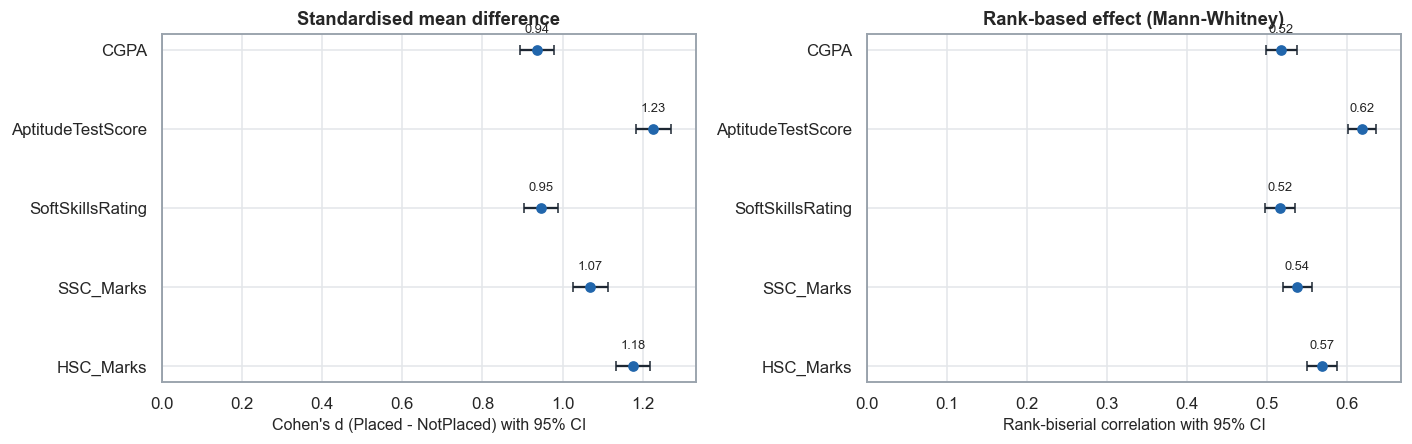

In [3]:
magd = lambda d: "negligible" if abs(d) < .2 else "small" if abs(d) < .5 else "medium" if abs(d) < .8 else "large"
for _, r in num_tests.iterrows():
    print(f"{r.feature:18s} U={r.mwu_U:,.0f}  Holm p={fp(r.p_mwu_holm):>9s}  d={r.cohens_d:.2f} [{r.d_ci_lo:.2f},{r.d_ci_hi:.2f}] ({magd(r.cohens_d)})  "
          f"AUC={r.auc:.3f}  r_rb={r.rank_biserial:.2f}  Welch agrees: {r.agrees_with_welch}")
print("\nSD ratios (Placed/NotPlaced):", num_tests.set_index("feature").sd_ratio_placed_over_notplaced.round(2).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
yy = np.arange(len(num_tests))[::-1]
for ax, (col, lo, hi, lab) in zip(axes, [("cohens_d", "d_ci_lo", "d_ci_hi", "Cohen's d (Placed - NotPlaced)"),
                                          ("rank_biserial", "rank_biserial_ci_lo", "rank_biserial_ci_hi", "Rank-biserial correlation")]):
    ax.errorbar(num_tests[col], yy, xerr=[num_tests[col] - num_tests[lo], num_tests[hi] - num_tests[col]], fmt="o", color=PLACED_C, ecolor="#1d2733", capsize=3, ms=6)
    for yi, v in zip(yy, num_tests[col]): ax.text(v, yi + 0.22, f"{v:.2f}", ha="center", fontsize=8.5)
    ax.axvline(0, color=NEUTRAL, lw=1); ax.set_yticks(yy); ax.set_yticklabels(num_tests.feature); ax.set_xlabel(lab + " with 95% CI"); ax.set_xlim(0, None)
axes[0].set_title("Standardised mean difference"); axes[1].set_title("Rank-based effect (Mann-Whitney)")
savefig(fig, "stat_01_numeric_effect_sizes")

**Interpretation.** Compare the *magnitude* column (d, r_rb, AUC), not just the p-values. The two tests agree on every feature
(Welch agreement flag), so the conclusions do not hinge on the normality assumption. Differences are statistically
distinguishable from zero for all five scores, and the effects are large by conventional benchmarks; this is a statement about
observed group differences in this dataset and does not imply that raising a score would change placement.

## 3. Binary categorical features: ExtracurricularActivities and PlacementTraining
**Research question:** is placement status associated with the feature?
**H0:** PlacementStatus is independent of the feature. **H1:** PlacementStatus is associated with the feature.

**Why Pearson's chi-square test of independence:** two categorical variables, independent observations, and (checked below) all expected
counts >= 5. If any expected count were < 5 the 2x2 test would switch to Fisher's exact test. No continuity correction is applied because
counts are large. **Effect sizes:** Cramer's V (0.1 small / 0.3 medium / 0.5 large for a 2x2) and the odds ratio (Yes vs No) with a Woolf 95% CI
(conventional OR benchmarks 1.68 small, 3.47 medium, 6.71 large).

In [4]:
def woolf_or(a, b, c, d_):
    # OR = (a*d)/(b*c); +0.5 to every cell if any is zero. Woolf (log-scale) 95% CI.
    if min(a, b, c, d_) == 0: a, b, c, d_ = a + .5, b + .5, c + .5, d_ + .5
    o = (a * d_) / (b * c); se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d_)
    return o, np.exp(np.log(o) - 1.96 * se), np.exp(np.log(o) + 1.96 * se)

def cramers_v(chi2, n, r, c): return np.sqrt(chi2 / (n * (min(r, c) - 1)))

def contingency(var, levels=None):
    t = pd.crosstab(df[var], df[TARGET]).reindex(columns=["Placed", "NotPlaced"])
    return t if levels is None else t.loc[levels]

cat_rows, ct_long = [], []
def omnibus(var, binary):
    t = contingency(var); chi2, p, dof, exp = stats.chi2_contingency(t.values, correction=False)
    n = t.values.sum(); rec = {"variable": var, "n_levels": len(t), "n": n, "min_expected_count": exp.min(),
                               "assumption_expected>=5": bool(exp.min() >= 5)}
    if exp.min() >= 5:
        rec.update({"test": "Pearson chi-square (no continuity correction)", "statistic": chi2, "dof": dof, "p_raw": p})
    elif t.shape == (2, 2):
        o, pf = stats.fisher_exact(t.values); rec.update({"test": "Fisher exact (two-sided)", "statistic": o, "dof": np.nan, "p_raw": pf})
    else:
        rec.update({"test": "Pearson chi-square (expected<5: interpret cautiously)", "statistic": chi2, "dof": dof, "p_raw": p})
    rec["chi2_for_effect_size"] = chi2; rec["cramers_v"] = cramers_v(chi2, n, *t.shape)
    if binary:
        o, lo, hi = woolf_or(t.loc["Yes", "Placed"], t.loc["Yes", "NotPlaced"], t.loc["No", "Placed"], t.loc["No", "NotPlaced"])
        rec.update({"odds_ratio_yes_vs_no": o, "or_ci_lo": lo, "or_ci_hi": hi})
    cat_rows.append(rec)
    e = pd.DataFrame(exp, index=t.index, columns=["expected_Placed", "expected_NotPlaced"])
    out = t.rename(columns={"Placed": "observed_Placed", "NotPlaced": "observed_NotPlaced"}).join(e)
    out["placement_rate_%"] = t.Placed / t.sum(axis=1) * 100; out.insert(0, "variable", var); out.index.name = "level"
    ct_long.append(out.reset_index()); return out

for v in CATB:
    print(f"=== {v} ===  (observed, expected, rate)"); display(omnibus(v, True).round(1))

=== ExtracurricularActivities ===  (observed, expected, rate)


,variable,observed_Placed,observed_NotPlaced,expected_Placed,expected_NotPlaced,placement_rate_%
level,,,,,,
No,ExtracurricularActivities,567,3577,1722.1,2421.9,13.7
Yes,ExtracurricularActivities,3552,2216,2396.9,3371.1,61.6


=== PlacementTraining ===  (observed, expected, rate)


,variable,observed_Placed,observed_NotPlaced,expected_Placed,expected_NotPlaced,placement_rate_%
level,,,,,,
No,PlacementTraining,418,2264,1114.5,1567.5,15.6
Yes,PlacementTraining,3701,3529,3004.5,4225.5,51.2


## 4. Internships (levels 0, 1, 2)
**Omnibus question:** is Internships associated with PlacementStatus? **H0:** placement rate is the same at all three levels. **H1:** at least one level differs.
Test: Pearson chi-square (3x2). The EDA showed a visibly non-monotonic pattern (33.4% / 32.6% / 69.0%), so **no trend test is used**: a
trend test assumes steady ordered change, which the data contradict.

**Planned pairwise comparisons (Holm across the 3):** 0 vs 1, 1 vs 2, 0 vs 2. For a comparison "A vs B", **difference = rate(B) - rate(A)** and
**OR = odds(B) / odds(A)**. Test choice: two-proportion z-test (equivalently an uncorrected 2x2 chi-square) when all expected counts >= 5 and both
groups have n >= 50, otherwise Fisher's exact test. Rate-difference CI: Newcombe hybrid-score interval; OR CI: Woolf.
For each comparison H0: the two placement rates are equal; H1: they differ.

In [5]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def newcombe(k1, n1, k0, n0):
    # CI for p1 - p0 (Newcombe hybrid score method)
    p1, p0 = k1 / n1, k0 / n0; l1, u1 = wilson(k1, n1); l0, u0 = wilson(k0, n0)
    d = p1 - p0
    return d, d - np.sqrt((p1 - l1) ** 2 + (u0 - p0) ** 2), d + np.sqrt((u1 - p1) ** 2 + (p0 - l0) ** 2)

def pair_test(var, A, B, family):
    mA, mB = df[var] == A, df[var] == B
    kA, nA, kB, nB = int(y[mA].sum()), int(mA.sum()), int(y[mB].sum()), int(mB.sum())
    tab = np.array([[kB, nB - kB], [kA, nA - kA]])
    chi2, p_chi, _, exp = stats.chi2_contingency(tab, correction=False)
    d, dlo, dhi = newcombe(kB, nB, kA, nA); o, olo, ohi = woolf_or(kB, nB - kB, kA, nA - kA)
    if exp.min() < 5 or min(nA, nB) < 50:
        orr, p = stats.fisher_exact(tab); test, stat = "Fisher exact (two-sided)", orr
    else:
        p = p_chi; test, stat = "Two-proportion z-test", np.sign(d) * np.sqrt(chi2)
    return {"family": family, "variable": var, "comparison": f"{A} vs {B}", "level_A": A, "level_B": B, "n_A": nA, "n_B": nB,
            "placed_A": kA, "placed_B": kB, "rate_A_%": kA / nA * 100, "rate_B_%": kB / nB * 100,
            "diff_pp (B-A)": d * 100, "diff_ci_lo_pp": dlo * 100, "diff_ci_hi_pp": dhi * 100,
            "odds_ratio (B vs A)": o, "or_ci_lo": olo, "or_ci_hi": ohi, "min_expected": exp.min(),
            "test": test, "statistic": stat, "p_raw": p}

PAIRS = {"Internships": [(0, 1), (1, 2), (0, 2)],
         "Workshops/Certifications": [(0, 1), (1, 2), (2, 3), (0, 2), (0, 3)],
         "Projects": [(0, 1), (0, 2), (0, 3), (1, 2), (2, 3)]}
pair_frames = {}
def run_family(var):
    f = pd.DataFrame([pair_test(var, a, b, f"{var} pairwise") for a, b in PAIRS[var]])
    f["p_holm"] = holm(f.p_raw); f["significant_holm"] = f.p_holm < ALPHA; pair_frames[var] = f; return f
PW_COLS = ["comparison", "rate_A_%", "rate_B_%", "diff_pp (B-A)", "diff_ci_lo_pp", "diff_ci_hi_pp", "odds_ratio (B vs A)", "or_ci_lo", "or_ci_hi",
           "test", "statistic", "p_raw", "p_holm", "significant_holm"]

omnibus("Internships", False)
t_int = contingency("Internships"); chi2, p, dof, exp = stats.chi2_contingency(t_int.values, correction=False)
print(f"Overall chi-square (3x2): chi2={chi2:.1f}, df={dof}, p={fp(p)}, Cramer's V={cramers_v(chi2, t_int.values.sum(), 3, 2):.3f}, min expected={exp.min():.0f}")
pw_int = run_family("Internships")
show(pw_int[PW_COLS].set_index("comparison"), ["p_raw", "p_holm"])

Overall chi-square (3x2): chi2=976.7, df=2, p=8.19e-213, Cramer's V=0.314, min expected=824


,rate_A_%,rate_B_%,diff_pp (B-A),diff_ci_lo_pp,diff_ci_hi_pp,odds_ratio (B vs A),or_ci_lo,or_ci_hi,test,statistic,p_raw,p_holm,significant_holm
comparison,,,,,,,,,,,,,
0 vs 1,33.4342,32.6107,-0.8235,-3.2593,1.5695,0.9634,0.8640,1.0743,Two-proportion z-test,-0.6701,0.5028,0.5028,False
1 vs 2,32.6107,68.9641,36.3534,34.0956,38.5473,4.5919,4.1415,5.0912,Two-proportion z-test,29.9702,2.40e-197,7.21e-197,True
0 vs 2,33.4342,68.9641,35.5299,32.7047,38.2668,4.4240,3.8953,5.0246,Two-proportion z-test,23.4409,1.64e-121,3.27e-121,True


In [6]:
r = pw_int.set_index("comparison")
print("0 vs 1 : difference %+.1f pp, 95%% CI [%+.1f, %+.1f], Holm p = %s" % (r.loc["0 vs 1", "diff_pp (B-A)"], r.loc["0 vs 1", "diff_ci_lo_pp"], r.loc["0 vs 1", "diff_ci_hi_pp"], fp(r.loc["0 vs 1", "p_holm"])))
print("1 vs 2 : difference %+.1f pp, 95%% CI [%+.1f, %+.1f], Holm p = %s" % (r.loc["1 vs 2", "diff_pp (B-A)"], r.loc["1 vs 2", "diff_ci_lo_pp"], r.loc["1 vs 2", "diff_ci_hi_pp"], fp(r.loc["1 vs 2", "p_holm"])))

0 vs 1 : difference -0.8 pp, 95% CI [-3.3, +1.6], Holm p = 0.5028
1 vs 2 : difference +36.4 pp, 95% CI [+34.1, +38.5], Holm p = 7.21e-197


**Discussion - 0 vs 1 versus 1 vs 2.** The 0-vs-1 difference is close to zero and its confidence interval is narrow and centred near zero,
while the 1-vs-2 difference is large. Failing to reject H0 for 0 vs 1 is *absence of evidence of a difference*, not proof of equality; the CI is the
better guide, because it bounds how large a 0-vs-1 difference is still compatible with the data. The data therefore describe a
**threshold-like (step) pattern** - nothing visible between 0 and 1 internships, then a large jump at 2 - not a steady dose-response. That
pattern is exactly why a single linear "Internships" slope would summarise it poorly. The step could arise from how the data were
generated, from other characteristics that differ between students with 2 internships (section 7 examines aptitude), or from real
differences in the population; these tests cannot tell which.

## 5. Workshops/Certifications (levels 0-3)
**Omnibus:** H0: placement rate is equal at all four levels; H1: at least one differs (Pearson chi-square, 4x2; no trend test because the pattern
is visibly non-monotonic: 28.4% / 21.1% / 72.6% / 56.3%).
**Planned pairwise (Holm across the 5):** 0 vs 1, 1 vs 2, 2 vs 3, 0 vs 2, 0 vs 3 - each H0: equal placement rates. Conventions as in section 4.

In [7]:
omnibus("Workshops/Certifications", False)
t = contingency("Workshops/Certifications"); chi2, p, dof, exp = stats.chi2_contingency(t.values, correction=False)
print(f"Overall chi-square (4x2): chi2={chi2:.1f}, df={dof}, p={fp(p)}, Cramer's V={cramers_v(chi2, t.values.sum(), 4, 2):.3f}, min expected={exp.min():.0f}")
pw_wk = run_family("Workshops/Certifications")
show(pw_wk[PW_COLS].set_index("comparison"), ["p_raw", "p_holm"])

Overall chi-square (4x2): chi2=2033.7, df=3, p=<1e-300, Cramer's V=0.453, min expected=118


,rate_A_%,rate_B_%,diff_pp (B-A),diff_ci_lo_pp,diff_ci_hi_pp,odds_ratio (B vs A),or_ci_lo,or_ci_hi,test,statistic,p_raw,p_holm,significant_holm
comparison,,,,,,,,,,,,,
0 vs 1,28.3534,21.0546,-7.2988,-9.3993,-5.1680,0.6739,0.5995,0.7576,Two-proportion z-test,-6.6270,3.43e-11,6.85e-11,True
1 vs 2,21.0546,72.6002,51.5456,49.3158,53.6785,9.9350,8.8027,11.2130,Two-proportion z-test,39.4047,<1e-300,<1e-300,True
2 vs 3,72.6002,56.3380,-16.2622,-22.2707,-10.4030,0.4870,0.3804,0.6234,Two-proportion z-test,-5.8064,6.38e-09,6.38e-09,True
0 vs 2,28.3534,72.6002,44.2468,42.1001,46.3237,6.6955,6.0270,7.4380,Two-proportion z-test,36.8059,1.48e-296,5.93e-296,True
0 vs 3,28.3534,56.3380,27.9846,21.9875,33.8068,3.2605,2.5519,4.1660,Two-proportion z-test,9.8901,4.59e-23,1.38e-22,True


**Interpretation.** Level 1 shows a *lower* observed rate than level 0 and level 3 a *lower* rate than level 2; the rows above give the size and
uncertainty of each step. The 2 vs 3 comparison involves only 284 students at level 3, so its interval is wider. Nothing here supports a claim that
workshops cause placement or that more workshops is better or worse; the pattern is a descriptive, non-monotonic association that section 7 probes further.

## 6. Projects (levels 0-3)
**Omnibus:** H0: equal placement rate at all four levels; H1: at least one differs (chi-square 4x2). The expected-count assumption is checked explicitly
because the Projects = 0 group has only **30 students**.
**Planned pairwise (Holm across the 5):** 0 vs 1, 0 vs 2, 0 vs 3 (the small group against each other level) and the adjacent comparisons 1 vs 2, 2 vs 3.
Comparisons involving Projects = 0 use **Fisher's exact test** (rule: any expected count < 5 or either group n < 50). Intervals for the small group are wide and
the 60% rate must not be over-interpreted.

In [8]:
omnibus("Projects", False)
t = contingency("Projects"); chi2, p, dof, exp = stats.chi2_contingency(t.values, correction=False)
print(f"Overall chi-square (4x2): chi2={chi2:.1f}, df={dof}, p={fp(p)}, Cramer's V={cramers_v(chi2, t.values.sum(), 4, 2):.3f}")
print("Expected counts (smallest cell = %.1f, in the Projects=0 / Placed cell: %.1f)" % (exp.min(), exp[0, 0]))
display(pd.DataFrame(exp, index=t.index, columns=["expected_Placed", "expected_NotPlaced"]).round(1))
pw_pr = run_family("Projects")
lo0, hi0 = wilson(18, 30); print(f"Projects = 0: 18/30 placed = 60.0%, Wilson 95% CI [{lo0*100:.1f}%, {hi0*100:.1f}%]  (n = 30)")
show(pw_pr[PW_COLS].set_index("comparison"), ["p_raw", "p_holm"])

Overall chi-square (4x2): chi2=2389.2, df=3, p=<1e-300, Cramer's V=0.491
Expected counts (smallest cell = 12.5, in the Projects=0 / Placed cell: 12.5)


,expected_Placed,expected_NotPlaced
Projects,,
0,12.5,17.5
1,1473.1,2071.9
2,1059.7,1490.3
3,1573.7,2213.3


Projects = 0: 18/30 placed = 60.0%, Wilson 95% CI [42.3%, 75.4%]  (n = 30)


,rate_A_%,rate_B_%,diff_pp (B-A),diff_ci_lo_pp,diff_ci_hi_pp,odds_ratio (B vs A),or_ci_lo,or_ci_hi,test,statistic,p_raw,p_holm,significant_holm
comparison,,,,,,,,,,,,,
0 vs 1,60.0000,16.8688,-43.1312,-58.5872,-25.4058,0.1353,0.0648,0.2823,Fisher exact (two-sided),0.1353,1.58e-07,4.73e-07,True
0 vs 2,60.0000,31.3725,-28.6275,-44.1386,-10.8533,0.3048,0.1461,0.6357,Fisher exact (two-sided),0.3048,0.0014,0.0027,True
0 vs 3,60.0000,71.3758,11.3758,-4.1029,29.1124,1.6624,0.7980,3.4628,Fisher exact (two-sided),1.6624,0.2222,0.2222,False
1 vs 2,16.8688,31.3725,14.5037,12.3246,16.6885,2.2528,1.9954,2.5435,Two-proportion z-test,13.2856,2.81e-40,1.12e-39,True
2 vs 3,31.3725,71.3758,40.0032,37.6634,42.2722,5.4546,4.8895,6.0851,Two-proportion z-test,31.4076,1.59e-216,7.97e-216,True


**Interpretation.** Overall, placement differs across Projects levels, and the adjacent comparisons among levels 1-3 are large. The Projects = 0 results rest on
30 students; its confidence interval spans a very wide range, so the 60% point estimate is weakly determined and should not be read as "no projects helps". Because
Fisher's exact test (not the z-test) is used for those pairs, and Holm adjusts across all five comparisons, comparisons with the small group have little power.

## 7. Interaction / confounding check: do Workshops and Projects patterns remain within aptitude bands?
**Question:** is the Workshops (or Projects) association with placement still present, and in the same direction, when students are compared
*within* aptitude bands? **Bands:** the same three aptitude terciles created in the EDA (`pd.qcut(AptitudeTestScore, 3)`); no new bins are introduced.
They are used only for stratification and are not saved as features.

**Method - Cochran-Mantel-Haenszel (CMH):**
1. **Omnibus (general association) CMH**, df = (levels - 1): H0: within every aptitude band, placement is independent of the count variable; H1: there is an association in at least one band.
2. **Stratified 2x2 contrasts** (same pairs as sections 5-6): Mantel-Haenszel pooled odds ratio of the higher vs lower level, H0: common OR = 1; H1: common OR != 1. Holm is applied across the 5 contrasts of each variable.
   The **Breslow-Day** test checks whether the OR is homogeneous across bands (an interaction check).
3. Compare the **crude OR** (ignoring aptitude) with the **aptitude-stratified MH OR**: if the stratified OR is much closer to 1, aptitude accounts for part of the crude pattern.

**Assumptions:** independent observations; a common-OR model (checked by Breslow-Day); adequate counts in strata (strata with a zero margin are dropped and reported; thin strata, e.g. Projects = 0, are flagged).
This is stratification on **one** coarse variable: it does **not** amount to causal adjustment, and residual confounding by other variables remains possible.

In [9]:
apt_band, edges = pd.qcut(df["AptitudeTestScore"], 3, labels=["Low", "Mid", "High"], duplicates="drop", retbins=True)
assert apt_band.nunique() == 3
print("Aptitude band edges:", edges, "| band sizes:", apt_band.value_counts().sort_index().to_dict())
BANDS = ["Low", "Mid", "High"]

def band_table(var, A, B, h):
    m = apt_band == h
    kA, nA = int(y[m & (df[var] == A)].sum()), int((m & (df[var] == A)).sum())
    kB, nB = int(y[m & (df[var] == B)].sum()), int((m & (df[var] == B)).sum())
    return np.array([[kB, nB - kB], [kA, nA - kA]])          # rows: B, A ; cols: Placed, NotPlaced  -> OR = odds(B)/odds(A)

def cmh_general(var, levels):
    # Generalised Cochran-Mantel-Haenszel (general association) for R x 2 x K tables; statistic ~ chi2(R-1)
    R = len(levels); dsum = np.zeros(R - 1); Vsum = np.zeros((R - 1, R - 1)); used = 0
    for h in BANDS:
        sub = df[(apt_band == h) & df[var].isin(levels)]
        t = pd.crosstab(sub[var], sub[TARGET]).reindex(index=levels, columns=["Placed", "NotPlaced"], fill_value=0).to_numpy(float)
        N = t.sum(); ni = t.sum(axis=1); m1, m2 = t[:, 0].sum(), t[:, 1].sum()
        if N <= 1 or m1 == 0 or m2 == 0: continue
        used += 1; ni_ = ni[:R - 1]
        dsum += t[:R - 1, 0] - ni_ * m1 / N
        Vsum += m1 * m2 / (N**2 * (N - 1)) * (N * np.diag(ni_) - np.outer(ni_, ni_))
    Q = float(dsum @ np.linalg.solve(Vsum, dsum)); return Q, R - 1, stats.chi2.sf(Q, R - 1), used

def mh_contrast(var, A, B):
    tabs = [band_table(var, A, B, h) for h in BANDS]
    keep = [t for t in tabs if (t.sum(axis=0) > 0).all() and (t.sum(axis=1) > 0).all()]
    st = StratifiedTable(keep); nt = st.test_null_odds(correction=False); lo, hi = st.oddsratio_pooled_confint()
    bd = st.test_equal_odds(adjust=False) if len(keep) > 1 else None
    return st, nt, (lo, hi), bd, len(keep), min(t.min() for t in tabs)

# validate the hand-written generalised CMH against statsmodels on a 2-level case
Qv, dfv, pv, _ = cmh_general("Workshops/Certifications", [0, 1])
st_chk = StratifiedTable([band_table("Workshops/Certifications", 0, 1, h) for h in BANDS]).test_null_odds(correction=False)
assert np.isclose(Qv, st_chk.statistic) and np.isclose(pv, st_chk.pvalue), "CMH implementation mismatch"
print("Validation passed: general CMH (R=2) equals statsmodels MH test (chi2 = %.3f)." % Qv)

Aptitude band edges: [60. 76. 84. 90.] | band sizes: {'Low': 3610, 'Mid': 3091, 'High': 3211}
Validation passed: general CMH (R=2) equals statsmodels MH test (chi2 = 22.999).


In [10]:
strat_rows, om_rows = [], []
for var in ["Workshops/Certifications", "Projects"]:
    levels = [0, 1, 2, 3]
    Q, dfree, p, used = cmh_general(var, levels)
    t = contingency(var); chi2c, pc, _, _ = stats.chi2_contingency(t.values, correction=False)
    om_rows.append({"kind": "omnibus_general_association_CMH", "variable": var, "comparison": "all levels", "crude_chi2": chi2c, "crude_dof": 3, "crude_p": pc,
                    "cmh_statistic": Q, "cmh_dof": dfree, "p_raw": p, "strata_used": used})
    for A, B in PAIRS[var]:
        st, nt, (lo, hi), bd, kept, mincell = mh_contrast(var, A, B)
        crude = pair_frames[var].set_index("comparison").loc[f"{A} vs {B}"]
        strat_rows.append({"kind": "contrast_MH", "variable": var, "comparison": f"{A} vs {B}",
                           "crude_or": crude["odds_ratio (B vs A)"], "crude_or_ci_lo": crude.or_ci_lo, "crude_or_ci_hi": crude.or_ci_hi,
                           "mh_or": st.oddsratio_pooled, "mh_or_ci_lo": lo, "mh_or_ci_hi": hi,
                           "cmh_statistic": nt.statistic, "p_raw": nt.pvalue,
                           "breslow_day_stat": np.nan if bd is None else bd.statistic, "breslow_day_p": np.nan if bd is None else bd.pvalue,
                           "strata_used": kept, "min_cell_count": mincell})
om = pd.DataFrame(om_rows); om["p_holm"] = holm(om.p_raw); om["significant_holm"] = om.p_holm < ALPHA
ct_ = pd.DataFrame(strat_rows)
ct_["p_holm"] = np.nan
for var in ["Workshops/Certifications", "Projects"]:
    m = ct_.variable == var; ct_.loc[m, "p_holm"] = holm(ct_.loc[m, "p_raw"])
ct_["significant_holm"] = ct_.p_holm < ALPHA
ct_["or_ratio_mh_over_crude"] = ct_.mh_or / ct_.crude_or
stratified = pd.concat([om, ct_], ignore_index=True)
stratified.to_csv(OUT / "04_stratified_tests.csv", index=False)
print("--- Omnibus (generalised CMH, df = 3; Holm across the 2 omnibus tests) ---")
show(om.set_index("variable")[["crude_chi2", "crude_p", "cmh_statistic", "cmh_dof", "p_raw", "p_holm", "significant_holm"]], ["crude_p", "p_raw", "p_holm"])

--- Omnibus (generalised CMH, df = 3; Holm across the 2 omnibus tests) ---


,crude_chi2,crude_p,cmh_statistic,cmh_dof,p_raw,p_holm,significant_holm
variable,,,,,,,
Workshops/Certifications,2033.7204,<1e-300,725.7105,3,5.58e-157,5.58e-157,True
Projects,2389.2017,<1e-300,854.1468,3,7.81e-185,1.56e-184,True


In [11]:
print("--- Contrasts: crude OR vs aptitude-stratified Mantel-Haenszel OR (OR = higher level vs lower level) ---")
cols = ["crude_or", "crude_or_ci_lo", "crude_or_ci_hi", "mh_or", "mh_or_ci_lo", "mh_or_ci_hi", "or_ratio_mh_over_crude", "cmh_statistic",
        "p_raw", "p_holm", "significant_holm", "breslow_day_p", "strata_used", "min_cell_count"]
for var in ["Workshops/Certifications", "Projects"]:
    print(f"=== {var} ==="); display(show(ct_[ct_.variable == var].set_index("comparison")[cols], ["p_raw", "p_holm", "breslow_day_p"]))

--- Contrasts: crude OR vs aptitude-stratified Mantel-Haenszel OR (OR = higher level vs lower level) ---
=== Workshops/Certifications ===


,crude_or,crude_or_ci_lo,crude_or_ci_hi,mh_or,mh_or_ci_lo,mh_or_ci_hi,or_ratio_mh_over_crude,cmh_statistic,p_raw,p_holm,significant_holm,breslow_day_p,strata_used,min_cell_count
comparison,,,,,,,,,,,,,,
0 vs 1,0.6739,0.5995,0.7576,0.7365,0.6498,0.8347,1.0928,22.9987,1.62e-06,3.24e-06,True,0.0836,3,144
1 vs 2,9.9350,8.8027,11.2130,4.6523,4.0591,5.3321,0.4683,529.7495,<1e-300,<1e-300,True,0.5695,3,120
2 vs 3,0.4870,0.3804,0.6234,0.6318,0.4837,0.8253,1.2974,12.0823,5.09e-04,5.09e-04,True,0.0357,3,20
0 vs 2,6.6955,6.0270,7.4380,3.5941,3.1962,4.0415,0.5368,478.9543,<1e-300,<1e-300,True,0.0071,3,120
0 vs 3,3.2605,2.5519,4.1660,2.2338,1.7152,2.9093,0.6851,37.5112,9.09e-10,2.73e-09,True,0.4302,3,20


=== Projects ===


,crude_or,crude_or_ci_lo,crude_or_ci_hi,mh_or,mh_or_ci_lo,mh_or_ci_hi,or_ratio_mh_over_crude,cmh_statistic,p_raw,p_holm,significant_holm,breslow_day_p,strata_used,min_cell_count
comparison,,,,,,,,,,,,,,
0 vs 1,0.1353,0.0648,0.2823,0.1874,0.0857,0.4101,1.3855,25.4662,4.50e-07,1.35e-06,True,0.1868,3,3
0 vs 2,0.3048,0.1461,0.6357,0.3283,0.1535,0.7023,1.0774,10.1109,0.0015,0.0029,True,0.3555,3,3
0 vs 3,1.6624,0.7980,3.4628,0.8720,0.4108,1.8508,0.5245,0.1431,0.7052,0.7052,False,0.1805,3,3
1 vs 2,2.2528,1.9954,2.5435,1.8612,1.6378,2.1150,0.8261,92.8263,<1e-300,<1e-300,True,0.0559,3,167
2 vs 3,5.4546,4.8895,6.0851,3.0026,2.6596,3.3898,0.5505,332.2462,<1e-300,<1e-300,True,0.0591,3,154


In [12]:
# Placement rates per level within each aptitude band (descriptive companion to the tests)
rates = []
for var in ["Workshops/Certifications", "Projects"]:
    g = y.groupby([df[var], apt_band], observed=True).agg(["sum", "size"]).reset_index(); g.columns = ["level", "band", "placed", "n"]
    g.insert(0, "variable", var); g["rate_%"] = g.placed / g.n * 100; g["n<30"] = g.n < 30; rates.append(g)
band_rates = pd.concat(rates); band_rates.to_csv(OUT / "04_stratified_rates.csv", index=False)
for var in ["Workshops/Certifications", "Projects"]:
    print(f"=== {var}: placement rate (%) by level and aptitude band ===")
    display(band_rates[band_rates.variable == var].pivot(index="level", columns="band", values="rate_%").reindex(columns=BANDS).round(1))
    display(band_rates[band_rates.variable == var].pivot(index="level", columns="band", values="n").reindex(columns=BANDS))

=== Workshops/Certifications: placement rate (%) by level and aptitude band ===


band,Low,Mid,High
level,,,
0,15.4,29.3,58.4
1,9.9,25.3,53.3
2,31.5,61.1,85.3
3,36.4,45.4,75.2


band,Low,Mid,High
level,,,
0,1724,1309,702
1,1450,834,390
2,381,840,1998
3,55,108,121


=== Projects: placement rate (%) by level and aptitude band ===


band,Low,Mid,High
level,,,
0,53.8,62.5,66.7
1,8.9,22.6,44.7
2,18.4,32.4,58.0
3,37.7,57.0,83.7


band,Low,Mid,High
level,,,
0,13,8,9
1,2093,1078,374
2,1096,959,495
3,408,1046,2333


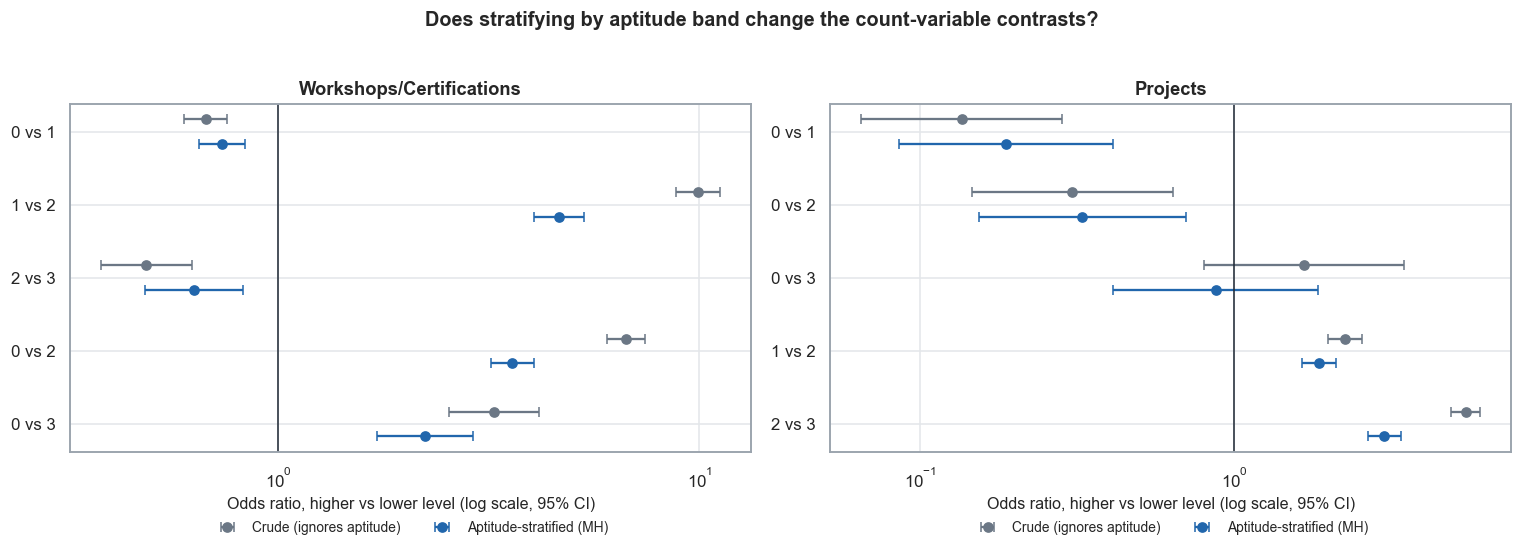

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, var in zip(axes, ["Workshops/Certifications", "Projects"]):
    s = ct_[ct_.variable == var].reset_index(drop=True); yy = np.arange(len(s))[::-1]
    for off, (pre, col, lab) in zip([0.17, -0.17], [("crude", NEUTRAL, "Crude (ignores aptitude)"), ("mh", PLACED_C, "Aptitude-stratified (MH)")]):
        ax.errorbar(s[f"{pre}_or"], yy + off, xerr=[s[f"{pre}_or"] - s[f"{pre}_or_ci_lo"], s[f"{pre}_or_ci_hi"] - s[f"{pre}_or"]], fmt="o", color=col, ecolor=col, capsize=3, ms=6, label=lab)
    ax.axvline(1, color="#1d2733", lw=1); ax.set_xscale("log"); ax.set_yticks(yy); ax.set_yticklabels(s.comparison)
    ax.set_xlabel("Odds ratio, higher vs lower level (log scale, 95% CI)"); ax.set_title(var); ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.suptitle("Does stratifying by aptitude band change the count-variable contrasts?", y=1.02, fontsize=13, fontweight="semibold")
savefig(fig, "stat_03_crude_vs_stratified_or")

**What the stratified analysis shows (read with the tables above).**
- *Does the association remain after stratifying by aptitude?* Check the omnibus CMH rows: a significant statistic means placement still differs across levels *within* aptitude bands.
- *Does aptitude explain part of the crude pattern?* Compare each contrast's MH OR with its crude OR (`or_ratio_mh_over_crude`; a value well below 1 for an OR above 1, or above 1 for an OR below 1, means the stratified association is weaker). Aptitude is a strong correlate of both the count variables and placement, so some attenuation is expected.
- *Are the non-monotonic features stable?* Look at whether the direction of the 0 vs 1 and 2 vs 3 workshop contrasts is unchanged within bands, and whether the Breslow-Day p-values suggest the OR differs across bands.
- Only one coarse variable (three aptitude terciles) is stratified, so differences that remain may still reflect other variables (e.g. extracurriculars) and this is **not a causal adjustment**.

## 8. Association and redundancy among predictors
Spearman (rank) and Pearson correlations among the eight numeric predictors, and variance inflation factors (VIF). VIF_j = 1 / (1 - R_j^2), where R_j^2 is
from regressing predictor j on all the others; common rules of thumb flag VIF > 5 (moderate) or > 10 (severe) concern. High correlation or VIF does
not by itself justify removing a variable; it mainly inflates the variance (and destabilises the sign/size) of individual coefficients in a logistic regression,
while leaving predictions largely unaffected. No variable is dropped here.

In [14]:
pear = df[NUM].corr(method="pearson"); spear = df[NUM].corr(method="spearman")
pear.round(4).to_csv(OUT / "04_pearson_matrix.csv"); spear.round(4).to_csv(OUT / "04_spearman_matrix.csv")
iu = np.triu_indices(len(NUM), 1)
pairs = pd.DataFrame({"pair": [f"{NUM[i]} / {NUM[j]}" for i, j in zip(*iu)], "pearson": pear.values[iu], "spearman": spear.values[iu]})
pairs["abs_max"] = pairs[["pearson", "spearman"]].abs().max(axis=1)
print("Strongest predictor-predictor associations:"); display(pairs.sort_values("abs_max", ascending=False).head(8).round(3).drop(columns="abs_max").reset_index(drop=True))
ah = pairs[pairs.pair == "AptitudeTestScore / HSC_Marks"].iloc[0]
print(f"Verification of the EDA value: AptitudeTestScore-HSC_Marks Pearson r = {ah.pearson:.3f}, Spearman rho = {ah.spearman:.3f}")
assert abs(ah.pearson - 0.56) < 0.01

def vif_table(X, label):
    Xc = add_constant(X.astype(float)); v = [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])]
    return pd.DataFrame({"set": label, "feature": X.columns, "vif": v})
enc = df[NUM].copy()
for c in CATB: enc[c] = (df[c] == "Yes").astype(float)
vif = pd.concat([vif_table(df[NUM], "numeric_8"), vif_table(enc, "all_10_binary_as_0/1")], ignore_index=True)
vif["concern"] = np.where(vif.vif > 10, "severe (>10)", np.where(vif.vif > 5, "moderate (>5)", "low (<=5)"))
vif.to_csv(OUT / "04_vif.csv", index=False)
display(vif.pivot(index="feature", columns="set", values="vif").round(2))

Strongest predictor-predictor associations:


,pair,pearson,spearman
0,AptitudeTestScore / HSC_Marks,0.559,0.554
1,AptitudeTestScore / Projects,0.535,0.547
2,AptitudeTestScore / SoftSkillsRating,0.509,0.539
3,HSC_Marks / Projects,0.530,0.515
4,SSC_Marks / HSC_Marks,0.521,0.492
5,AptitudeTestScore / SSC_Marks,0.509,0.505
6,SSC_Marks / Projects,0.495,0.489
7,CGPA / AptitudeTestScore,0.456,0.487


Verification of the EDA value: AptitudeTestScore-HSC_Marks Pearson r = 0.559, Spearman rho = 0.554


set,all_10_binary_as_0/1,numeric_8
feature,,
AptitudeTestScore,1.93,1.91
CGPA,1.49,1.46
ExtracurricularActivities,1.76,NaN
HSC_Marks,1.96,1.88
Internships,1.19,1.19
PlacementTraining,1.18,NaN
Projects,1.77,1.74
SSC_Marks,1.72,1.65
SoftSkillsRating,1.55,1.53


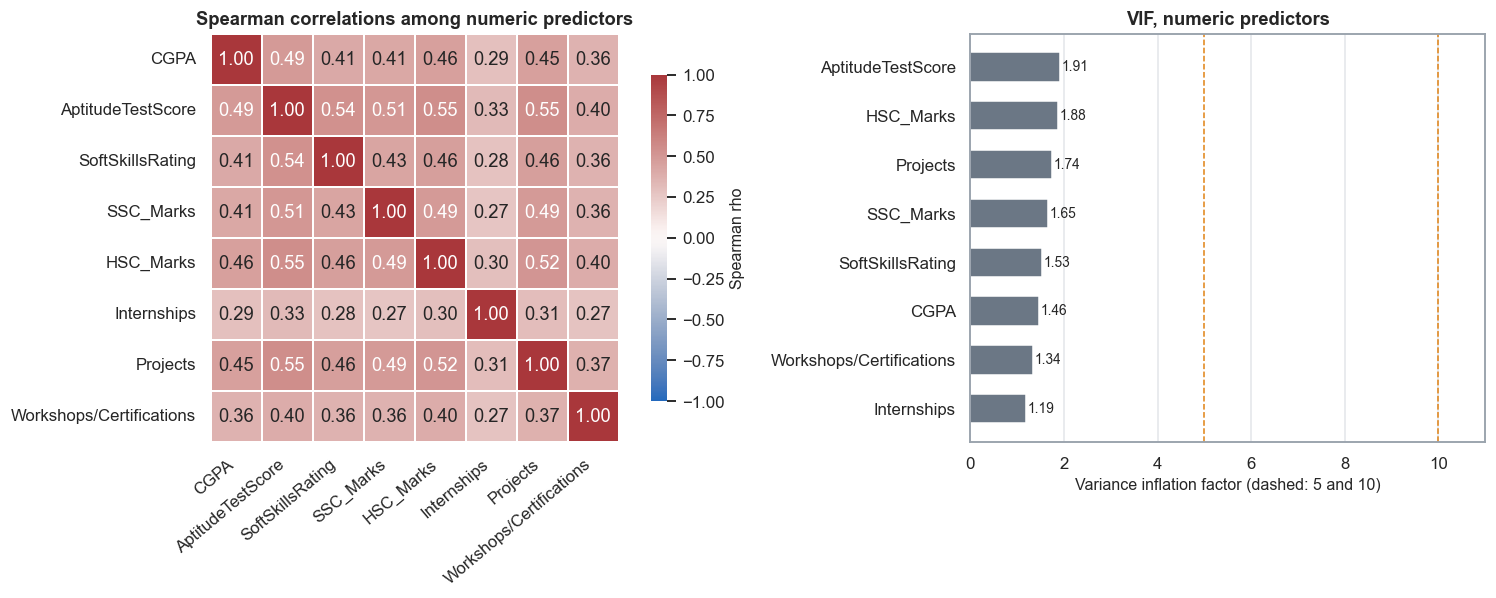

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(spear, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True, linewidths=1, linecolor="white", cbar_kws={"label": "Spearman rho", "shrink": .8}, ax=axes[0])
axes[0].set_title("Spearman correlations among numeric predictors"); axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=40, ha="right")
v = vif[vif["set"] == "numeric_8"].sort_values("vif"); axes[1].barh(v.feature, v.vif, color=NEUTRAL, height=.6)
for i, x in enumerate(v.vif): axes[1].text(x + .03, i, f"{x:.2f}", va="center", fontsize=9)
for t_, lab in [(5, "5"), (10, "10")]: axes[1].axvline(t_, color=NOT_C, ls="--", lw=1)
axes[1].set_xlim(0, max(11, v.vif.max() * 1.15)); axes[1].set_xlabel("Variance inflation factor (dashed: 5 and 10)"); axes[1].set_title("VIF, numeric predictors"); axes[1].grid(axis="y", visible=False)
savefig(fig, "stat_04_correlation_and_vif")

**Interpretation.** Predictors are moderately correlated with one another (the strongest pair is aptitude with HSC marks, verified above), which is expected if students strong on one measure
tend to be strong on others. VIF values summarise how much of each predictor is linearly predictable from the rest; compare them with the 5 / 10 rules of thumb in the figure.
For a logistic regression this means individual coefficients (especially for aptitude, HSC, SSC and Projects) may share explanatory credit and be less stable than their
marginal associations suggest; their *joint* predictive contribution is unaffected. Variables are kept; regularisation or coefficient-stability checks can be considered in modelling.

## 9. Effect-size summary
One table of every formal test with its effect size, CI, raw and adjusted p-values and a plain-language reading. Wording is deliberately descriptive
("larger observed difference"), not a predictive ranking. Magnitude labels use conventional benchmarks (Cohen's d, Cramer's V, rank-biserial, odds ratio) that are rough guides, not
domain-specific thresholds.

In [16]:
mag_v = lambda v: "negligible" if v < .1 else "small" if v < .3 else "medium" if v < .5 else "large"
mag_or = lambda o: "below the conventional 'small' threshold" if max(o, 1 / o) < 1.68 else "small" if max(o, 1 / o) < 3.47 else "medium" if max(o, 1 / o) < 6.71 else "large"
def reading(sig, label, mag):
    return ("Statistically supported" if sig else "Not statistically supported") + f" at alpha=0.05 (adjusted); {label} is {mag} by conventional benchmarks."

# categorical omnibus family (5 tests): holm across them
cat_tests = pd.DataFrame(cat_rows); cat_tests["p_holm"] = holm(cat_tests.p_raw); cat_tests["significant_holm"] = cat_tests.p_holm < ALPHA
cat_tests["family"] = "categorical association tests (5)"
cat_tests.drop(columns="chi2_for_effect_size").to_csv(OUT / "04_categorical_tests.csv", index=False)
pd.concat(ct_long).to_csv(OUT / "04_contingency_tables.csv", index=False)
display(show(cat_tests.set_index("variable")[["test", "statistic", "dof", "p_raw", "p_holm", "cramers_v", "min_expected_count", "assumption_expected>=5", "odds_ratio_yes_vs_no", "or_ci_lo", "or_ci_hi"]], ["p_raw", "p_holm"]))

pairwise = pd.concat(pair_frames.values(), ignore_index=True); pairwise.to_csv(OUT / "04_pairwise_tests.csv", index=False)

S = []
for _, r in num_tests.iterrows():
    S.append({"Feature": r.feature, "Test": "Mann-Whitney U (Holm, family of 5)", "Effect size measure": "Cohen's d", "Effect size": r.cohens_d, "CI lo": r.d_ci_lo, "CI hi": r.d_ci_hi,
              "Raw p": r.p_mwu, "Adjusted p": r.p_mwu_holm, "Significant (alpha=0.05)": r.significant_mwu_holm,
              "Practical interpretation": reading(r.significant_mwu_holm, f"d={r.cohens_d:.2f}, rank-biserial={r.rank_biserial:.2f} (AUC {r.auc:.2f})", magd(r.cohens_d))})
for _, r in cat_tests.iterrows():
    if pd.notna(r.get("odds_ratio_yes_vs_no", np.nan)):
        S.append({"Feature": r.variable, "Test": f"{r.test} (Holm, family of 5)", "Effect size measure": "Odds ratio (Yes vs No)", "Effect size": r.odds_ratio_yes_vs_no,
                  "CI lo": r.or_ci_lo, "CI hi": r.or_ci_hi, "Raw p": r.p_raw, "Adjusted p": r.p_holm, "Significant (alpha=0.05)": r.significant_holm,
                  "Practical interpretation": reading(r.significant_holm, f"OR={r.odds_ratio_yes_vs_no:.1f}, Cramer's V={r.cramers_v:.2f}", mag_or(r.odds_ratio_yes_vs_no))})
    else:
        S.append({"Feature": r.variable + " (overall)", "Test": f"{r.test} (Holm, family of 5)", "Effect size measure": "Cramer's V", "Effect size": r.cramers_v, "CI lo": np.nan, "CI hi": np.nan,
                  "Raw p": r.p_raw, "Adjusted p": r.p_holm, "Significant (alpha=0.05)": r.significant_holm,
                  "Practical interpretation": reading(r.significant_holm, f"V={r.cramers_v:.2f}", mag_v(r.cramers_v)) + " Non-monotonic: a trend summary would be inappropriate."})
for _, r in pairwise.iterrows():
    S.append({"Feature": f"{r.variable}: {r.comparison}", "Test": f"{r.test} (Holm within {r.variable} pairs)", "Effect size measure": "Odds ratio (B vs A)", "Effect size": r["odds_ratio (B vs A)"],
              "CI lo": r.or_ci_lo, "CI hi": r.or_ci_hi, "Raw p": r.p_raw, "Adjusted p": r.p_holm, "Significant (alpha=0.05)": r.significant_holm,
              "Practical interpretation": reading(r.significant_holm, f"rate difference {r['diff_pp (B-A)']:+.1f} pp [{r.diff_ci_lo_pp:+.1f}, {r.diff_ci_hi_pp:+.1f}], OR={r['odds_ratio (B vs A)']:.2f}", mag_or(r["odds_ratio (B vs A)"]))
              + (" Small group (n=%d): interpret cautiously." % min(r.n_A, r.n_B) if min(r.n_A, r.n_B) < 100 else "")})
for _, r in om.iterrows():
    S.append({"Feature": f"{r.variable} (aptitude-stratified, overall)", "Test": "Generalised CMH (Holm, family of 2)", "Effect size measure": "CMH chi-square (df=3)", "Effect size": r.cmh_statistic,
              "CI lo": np.nan, "CI hi": np.nan, "Raw p": r.p_raw, "Adjusted p": r.p_holm, "Significant (alpha=0.05)": r.significant_holm,
              "Practical interpretation": ("Statistically supported" if r.significant_holm else "Not statistically supported") + f" at alpha=0.05 (adjusted): association persists within aptitude bands (CMH chi2={r.cmh_statistic:.0f} vs crude chi2={r.crude_chi2:.0f}, i.e. attenuated but not removed). Stratified on aptitude tercile only; not a causal adjustment." if r.significant_holm else "Not statistically supported within aptitude bands."})
for _, r in ct_.iterrows():
    S.append({"Feature": f"{r.variable}: {r.comparison} (aptitude-stratified)", "Test": f"Mantel-Haenszel (Holm within {r.variable} contrasts)", "Effect size measure": "MH odds ratio (B vs A)", "Effect size": r.mh_or,
              "CI lo": r.mh_or_ci_lo, "CI hi": r.mh_or_ci_hi, "Raw p": r.p_raw, "Adjusted p": r.p_holm, "Significant (alpha=0.05)": r.significant_holm,
              "Practical interpretation": reading(r.significant_holm, f"MH OR={r.mh_or:.2f} vs crude {r.crude_or:.2f}", mag_or(r.mh_or)) + (" Thin strata: interpret cautiously." if r.min_cell_count < 5 else "")})
summ = pd.DataFrame(S); summ.to_csv(OUT / "04_effect_size_summary.csv", index=False)
print(summ.shape)
sx = summ.copy(); sx["Raw p"] = sx["Raw p"].map(fp); sx["Adjusted p"] = sx["Adjusted p"].map(fp)
sx[["Effect size", "CI lo", "CI hi"]] = sx[["Effect size", "CI lo", "CI hi"]].round(3)
display(sx)

,test,statistic,dof,p_raw,p_holm,cramers_v,min_expected_count,assumption_expected>=5,odds_ratio_yes_vs_no,or_ci_lo,or_ci_hi
variable,,,,,,,,,,,
ExtracurricularActivities,Pearson chi-square (no continuity correction),2278.0251,1,<1e-300,<1e-300,0.4794,1722.0678,True,10.1120,9.1199,11.2121
PlacementTraining,Pearson chi-square (no continuity correction),1021.0880,1,4.68e-224,9.37e-224,0.3210,1114.5236,True,5.6803,5.0679,6.3667
Internships,Pearson chi-square (no continuity correction),976.6943,2,8.19e-213,8.19e-213,0.3139,824.0493,True,NaN,NaN,NaN
Workshops/Certifications,Pearson chi-square (no continuity correction),2033.7204,3,<1e-300,<1e-300,0.4530,118.0182,True,NaN,NaN,NaN
Projects,Pearson chi-square (no continuity correction),2389.2017,3,<1e-300,<1e-300,0.4910,12.4667,True,NaN,NaN,NaN


(35, 10)


,Feature,Test,Effect size measure,Effect size,CI lo,CI hi,Raw p,Adjusted p,Significant (alpha=0.05),Practical interpretation
0,CGPA,"Mann-Whitney U (Holm, family of 5)",Cohen's d,0.936,0.894,0.979,<1e-300,<1e-300,True,"Statistically supported at alpha=0.05 (adjusted); d=0.94, rank-biserial=0.52 (AUC 0.76) is large by conventional ben..."
1,AptitudeTestScore,"Mann-Whitney U (Holm, family of 5)",Cohen's d,1.227,1.183,1.270,<1e-300,<1e-300,True,"Statistically supported at alpha=0.05 (adjusted); d=1.23, rank-biserial=0.62 (AUC 0.81) is large by conventional ben..."
2,SoftSkillsRating,"Mann-Whitney U (Holm, family of 5)",Cohen's d,0.945,0.903,0.987,<1e-300,<1e-300,True,"Statistically supported at alpha=0.05 (adjusted); d=0.95, rank-biserial=0.52 (AUC 0.76) is large by conventional ben..."
3,SSC_Marks,"Mann-Whitney U (Holm, family of 5)",Cohen's d,1.070,1.027,1.112,<1e-300,<1e-300,True,"Statistically supported at alpha=0.05 (adjusted); d=1.07, rank-biserial=0.54 (AUC 0.77) is large by conventional ben..."
4,HSC_Marks,"Mann-Whitney U (Holm, family of 5)",Cohen's d,1.176,1.132,1.219,<1e-300,<1e-300,True,"Statistically supported at alpha=0.05 (adjusted); d=1.18, rank-biserial=0.57 (AUC 0.78) is large by conventional ben..."
5,ExtracurricularActivities,"Pearson chi-square (no continuity correction) (Holm, family of 5)",Odds ratio (Yes vs No),10.112,9.120,11.212,<1e-300,<1e-300,True,"Statistically supported at alpha=0.05 (adjusted); OR=10.1, Cramer's V=0.48 is large by conventional benchmarks."
6,PlacementTraining,"Pearson chi-square (no continuity correction) (Holm, family of 5)",Odds ratio (Yes vs No),5.680,5.068,6.367,4.68e-224,9.37e-224,True,"Statistically supported at alpha=0.05 (adjusted); OR=5.7, Cramer's V=0.32 is medium by conventional benchmarks."
7,Internships (overall),"Pearson chi-square (no continuity correction) (Holm, family of 5)",Cramer's V,0.314,NaN,NaN,8.19e-213,8.19e-213,True,Statistically supported at alpha=0.05 (adjusted); V=0.31 is medium by conventional benchmarks. Non-monotonic: a tren...
8,Workshops/Certifications (overall),"Pearson chi-square (no continuity correction) (Holm, family of 5)",Cramer's V,0.453,NaN,NaN,<1e-300,<1e-300,True,Statistically supported at alpha=0.05 (adjusted); V=0.45 is medium by conventional benchmarks. Non-monotonic: a tren...
9,Projects (overall),"Pearson chi-square (no continuity correction) (Holm, family of 5)",Cramer's V,0.491,NaN,NaN,<1e-300,<1e-300,True,Statistically supported at alpha=0.05 (adjusted); V=0.49 is medium by conventional benchmarks. Non-monotonic: a tren...


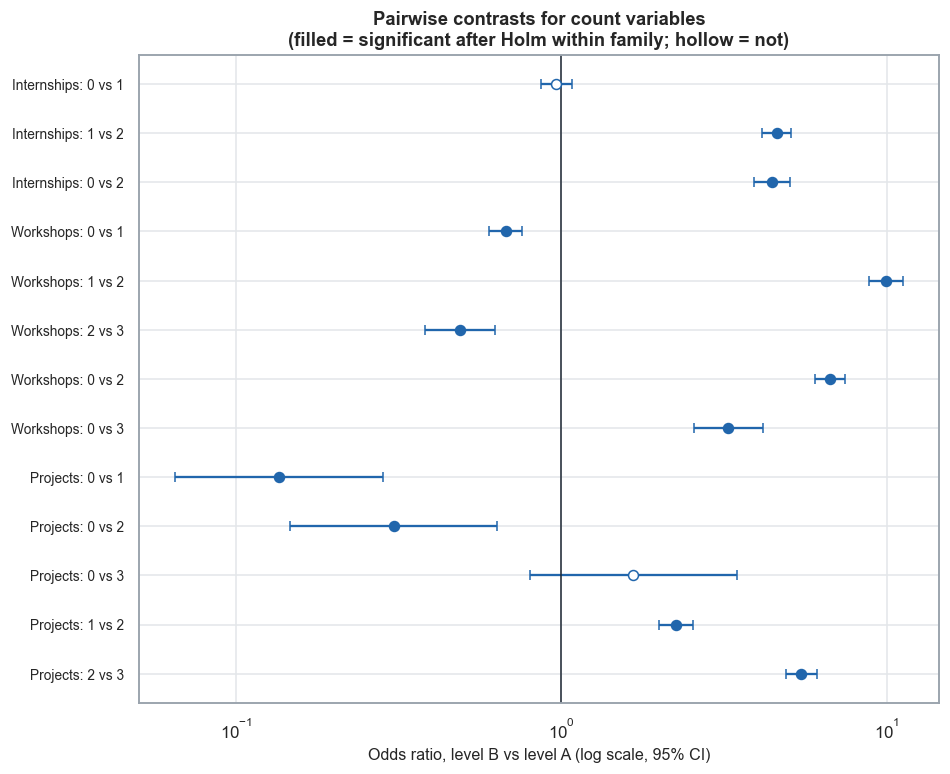

In [17]:
pw = pairwise.copy(); pw["lab"] = pw.variable.str.replace("Workshops/Certifications", "Workshops") + ": " + pw.comparison
fig, ax = plt.subplots(figsize=(8.8, 7.2)); yy = np.arange(len(pw))[::-1]
for yi, (_, r) in zip(yy, pw.iterrows()):
    c_ = PLACED_C
    ax.errorbar(r["odds_ratio (B vs A)"], yi, xerr=[[r["odds_ratio (B vs A)"] - r.or_ci_lo], [r.or_ci_hi - r["odds_ratio (B vs A)"]]], fmt="o", color=c_, ecolor=c_,
                mfc=c_ if r.significant_holm else "white", capsize=3, ms=6.5)
ax.axvline(1, color="#1d2733", lw=1); ax.set_xscale("log"); ax.set_yticks(yy); ax.set_yticklabels(pw.lab, fontsize=9)
ax.set_xlabel("Odds ratio, level B vs level A (log scale, 95% CI)")
ax.set_title("Pairwise contrasts for count variables\n(filled = significant after Holm within family; hollow = not)")
savefig(fig, "stat_02_pairwise_odds_ratios")

## 10. Multiple-comparison families
| Family | Tests | Correction |
|---|---|---|
| Numeric score tests | 5 Mann-Whitney tests (CGPA, aptitude, soft skills, SSC, HSC); the Welch sensitivity p-values get their own Holm pass | Holm within the 5 |
| Categorical association tests | 5 chi-square tests (2 binary predictors + 3 omnibus count tests) | Holm within the 5 |
| Internships pairwise | 0 vs 1, 1 vs 2, 0 vs 2 | Holm within the 3 |
| Workshops pairwise | 0v1, 1v2, 2v3, 0v2, 0v3 | Holm within the 5 |
| Projects pairwise | 0v1, 0v2, 0v3, 1v2, 2v3 | Holm within the 5 |
| Stratified omnibus (CMH) | Workshops, Projects | Holm within the 2 |
| Stratified MH contrasts, Workshops | the 5 pairs above | Holm within the 5 |
| Stratified MH contrasts, Projects | the 5 pairs above | Holm within the 5 |

The categorical-omnibus and stratified families are *additions* of this notebook (they group tests that answer the same type of question); they are never mixed with the numeric or pairwise families.
Descriptive quantities (correlations, VIF, train-only replication) are not hypothesis tests and are not adjusted.

In [18]:
fam = []
for name, p_raw, p_adj in [("Numeric scores (MWU)", num_tests.p_mwu, num_tests.p_mwu_holm), ("Numeric scores (Welch, sensitivity)", num_tests.p_welch, num_tests.p_welch_holm),
                           ("Categorical association", cat_tests.p_raw, cat_tests.p_holm)] + \
                          [(f"{v} pairwise", pair_frames[v].p_raw, pair_frames[v].p_holm) for v in PAIRS] + \
                          [("Stratified omnibus CMH", om.p_raw, om.p_holm)] + \
                          [(f"Stratified MH contrasts: {v}", ct_[ct_.variable == v].p_raw, ct_[ct_.variable == v].p_holm) for v in ["Workshops/Certifications", "Projects"]]:
    fam.append({"family": name, "n_tests": len(p_raw), "significant_raw": int((p_raw < ALPHA).sum()), "significant_holm": int((p_adj < ALPHA).sum()),
                "FWER_if_unadjusted_%": round((1 - (1 - ALPHA) ** len(p_raw)) * 100, 1)})
fam = pd.DataFrame(fam); display(fam)

,family,n_tests,significant_raw,significant_holm,FWER_if_unadjusted_%
0,Numeric scores (MWU),5,5,5,22.6
1,"Numeric scores (Welch, sensitivity)",5,5,5,22.6
2,Categorical association,5,5,5,22.6
3,Internships pairwise,3,2,2,14.3
4,Workshops/Certifications pairwise,5,5,5,22.6
5,Projects pairwise,5,4,4,22.6
6,Stratified omnibus CMH,2,2,2,9.8
7,Stratified MH contrasts: Workshops/Certifications,5,5,5,22.6
8,Stratified MH contrasts: Projects,5,4,4,22.6


## 11. Train / validation / test policy and replication on the training split
| Stage | Data | Purpose |
|---|---|---|
| **Exploratory / inferential analysis** (EDA, this notebook) | modelling dataset (all 9,912 profiles) | *Describe and test associations.* Outputs are summaries about the data, not models. |
| **Model fitting** (Phase 4) | **train** only | Estimate parameters (and fit any preprocessing: scaling, encoding). |
| **Model selection / tuning** | **validation** only | Compare candidate models, choose hyper-parameters and thresholds. |
| **Final evaluation** | **test**, used **once** | Report final performance. The test set must never be used to tune or select models, to choose features, or to decide preprocessing. |

Because this notebook used all rows (including those later reserved for validation/test) to *understand* the data, any modelling decision it motivates
(e.g. treating count variables as categorical) should be justified on the training data and checked on validation, not on the test set. As a safeguard, the table below
**replicates the key tests on the training split alone**: if the conclusions depend on rows later held out, that would show up here.

In [19]:
tr = splits["train"]; ytr = (tr[TARGET] == "Placed").astype(int)
rep = []
for c in CONT:
    a, b = tr.loc[ytr == 1, c], tr.loc[ytr == 0, c]
    rep.append({"feature": c, "measure": "Cohen's d", "full_modeling_data": num_tests.set_index("feature").loc[c, "cohens_d"], "train_only": cohens_d_ci(a, b)[0],
                "p_mwu_train_only": stats.mannwhitneyu(a, b, method="asymptotic").pvalue})
for c in CATB:
    t = pd.crosstab(tr[c], tr[TARGET]).reindex(columns=["Placed", "NotPlaced"]); o = woolf_or(*t.loc["Yes"], *t.loc["No"])[0]
    rep.append({"feature": c, "measure": "odds ratio (Yes vs No)", "full_modeling_data": cat_tests.set_index("variable").loc[c, "odds_ratio_yes_vs_no"], "train_only": o,
                "p_mwu_train_only": stats.chi2_contingency(t.values, correction=False)[1]})
for c in COUNT:
    t = pd.crosstab(tr[c], tr[TARGET]).reindex(columns=["Placed", "NotPlaced"]); chi2, p, _, _ = stats.chi2_contingency(t.values, correction=False)
    rep.append({"feature": c + " (overall)", "measure": "Cramer's V", "full_modeling_data": cat_tests.set_index("variable").loc[c, "cramers_v"], "train_only": cramers_v(chi2, t.values.sum(), *t.shape),
                "p_mwu_train_only": p})
rep = pd.DataFrame(rep).rename(columns={"p_mwu_train_only": "p_train_only"}); rep["conclusion_unchanged (p<.05)"] = rep.p_train_only < ALPHA
rep.to_csv(OUT / "04_train_only_replication.csv", index=False)
# count-variable step pattern on train alone
steps = {c: (ytr.groupby(tr[c]).mean() * 100).round(1).to_dict() for c in COUNT}
print("Placement rate (%) by level, train only:", steps)
show(rep.set_index("feature"), ["p_train_only"])

Placement rate (%) by level, train only: {'Internships': {0: 33.6, 1: 32.1, 2: 69.7}, 'Projects': {0: 57.9, 1: 16.9, 2: 31.3, 3: 71.0}, 'Workshops/Certifications': {0: 28.3, 1: 20.5, 2: 72.6, 3: 56.2}}


,measure,full_modeling_data,train_only,p_train_only,conclusion_unchanged (p<.05)
feature,,,,,
CGPA,Cohen's d,0.9365,0.9486,5.63e-305,True
AptitudeTestScore,Cohen's d,1.2266,1.2252,<1e-300,True
SoftSkillsRating,Cohen's d,0.9454,0.9543,6.97e-303,True
SSC_Marks,Cohen's d,1.0697,1.0860,<1e-300,True
HSC_Marks,Cohen's d,1.1755,1.1684,<1e-300,True
ExtracurricularActivities,odds ratio (Yes vs No),10.1120,10.0654,<1e-300,True
PlacementTraining,odds ratio (Yes vs No),5.6803,6.0131,9.08e-164,True
Internships (overall),Cramer's V,0.3139,0.3240,6.43e-159,True
Projects (overall),Cramer's V,0.4910,0.4878,<1e-300,True


## 12. Statistical limitations
- **Observational data, no causal inference.** Associations may reflect shared underlying factors (overall academic strength, selection into activities); nothing here shows that changing a feature would change placement.
- **Possible synthetic or rule-based structure.** The hard floors and ceilings, very large effects across all predictors and step-like count patterns are *consistent with* synthetic or rule-based generation, but there is no direct evidence of this (the dataset card is silent on provenance). If true, p-values describe the generating rule, not a real student population.
- **Bounded feature ranges.** All scores are truncated (e.g. aptitude 60-90, CGPA 6.5-9.1) with pile-ups at the limits; distributions are non-normal, so rank-based tests are primary, and results do not extrapolate outside these ranges.
- **Duplicate/conflicting-label cleanup.** 72 duplicate rows were collapsed and 16 rows (8 conflicting profiles, all at the top of the range) were excluded in notebook 02. This removes label noise at the high end and could slightly overstate separability there.
- **Class imbalance.** About 58/42; chi-square and rank tests are fine, but accuracy-style summaries and some model behaviours later will need care.
- **Small subgroups.** Projects = 0 (n = 30) and Workshops = 3 (n = 284) give wide intervals; thin strata in section 7 limit the stratified analysis.
- **Multiple comparisons.** Holm is applied within defined families; across the whole notebook many tests are run, and the family definitions are a modelling choice. Effect sizes and CIs should lead.
- **Large-n sensitivity.** With about 10,000 rows, tiny differences become "significant"; statistical significance is not practical importance.
- **Multicollinearity.** Predictors are moderately inter-correlated (section 8); marginal tests do not isolate unique contributions.
- **One stratifying variable.** The CMH analysis conditions on aptitude terciles only (coarse), so residual confounding by other variables is possible.
- **Representativeness.** The data come from one unnamed campus ("XYZ"); generalising to other institutions or years is unwarranted.
- **Analysis used all modelling rows;** the policy and train-only replication in section 11 limit, but do not eliminate, the risk of analysis choices being informed by held-out rows.

## 13. Final findings

﻿> All results are associations in observational (possibly synthetic or rule-based) data. None is a causal claim, and p-values below about 1e-300 are shown as "<1e-300" because they underflow double precision.

### A. Statistically supported associations (Holm-adjusted p < 0.05 within family)
- **All five scores differ between Placed and NotPlaced** (Mann-Whitney, confirmed by Welch): Cohen's d from 0.94 (CGPA) to 1.23 (AptitudeTestScore); AUC from 0.76 to 0.81. Welch and Mann-Whitney agree on every feature.
- **ExtracurricularActivities:** OR = 10.1 (95% CI 9.1-11.2), Cramer's V = 0.48. **PlacementTraining:** OR = 5.7 (5.1-6.4), V = 0.32. Chi-square assumptions were met (smallest expected count > 1,100).
- **Internships, Workshops/Certifications and Projects** are each associated with placement overall (Cramer's V = 0.31, 0.45, 0.49).
- **Pairwise:** Internships 1 vs 2 (+36.4 pp), 0 vs 2 (+35.5 pp); Workshops 0 vs 1 (-7.3 pp), 1 vs 2 (+51.5 pp), 2 vs 3 (-16.3 pp), 0 vs 2, 0 vs 3; Projects 1 vs 2 (+14.5 pp), 2 vs 3 (+40.0 pp), and 0 vs 1 and 0 vs 2 (based on only 30 students at level 0).
- **All of these were replicated on the training split alone** with the same direction and significance (effect sizes within about 0.03 in d, 0.3 in OR for training).

### B. Associations that were not statistically supported
- **Internships 0 vs 1:** -0.8 pp (95% CI -3.3 to +1.6), Holm p = 0.50. This is absence of evidence of a difference, not proof of equality; differences larger than roughly 3 pp in either direction are unlikely given the data.
- **Projects 0 vs 3:** +11.4 pp (CI -4.1 to +29.1), Holm p = 0.22. The comparison is underpowered because Projects = 0 has only 30 students.
- Aptitude-stratified Projects 0 vs 3: MH OR = 0.87 (0.41-1.85), p = 0.71.

### C. Non-monotonic relationships
- **Internships:** flat from 0 to 1, then a large jump at 2 (a step, not a trend).
- **Workshops/Certifications:** statistically supported dips at 0 -> 1 (OR 0.67, 0.60-0.76) and 2 -> 3 (OR 0.49, 0.38-0.62). Trend tests would be inappropriate.
- **Projects:** the 60% rate at level 0 rests on 30 students (Wilson CI 42-75%) and is weakly determined.
- **After stratifying by aptitude tercile:** the large upward steps shrink substantially (Workshops 1 -> 2: crude OR 9.9 -> MH OR 4.7; 0 -> 2: 6.7 -> 3.6; Projects 2 -> 3: 5.5 -> 3.0; 1 -> 2: 2.25 -> 1.86), so aptitude accounts for part of those differences. The non-monotonic dips **persist** (Workshops 0 -> 1: MH OR 0.74, 0.65-0.83; 2 -> 3: 0.63, 0.48-0.83), so they are not explained by aptitude alone. Breslow-Day tests suggest the ORs are not homogeneous across bands for Workshops 0 vs 2 (p = 0.007) and 2 vs 3 (p = 0.036). Only one coarse variable was stratified, so other covariates (e.g. extracurriculars, which co-vary strongly with Workshops) may contribute.

### D. Important effect sizes (practical, not just statistical, importance)
- Scores: d about 0.9-1.2 (large by convention). Binary predictors: OR 10.1 (extracurricular) and 5.7 (training). Count variables: Cramer's V 0.31-0.49 (medium).
- Biggest single contrasts: Workshops 1 vs 2 (OR 9.9, +51.5 pp crude) and Projects 2 vs 3 (OR 5.5, +40.0 pp crude); these are the contrasts most attenuated by aptitude stratification.
- Because n is about 10,000, even small differences yield tiny p-values; effect sizes and CIs, not p-values, should guide interpretation.

### E. Potential multicollinearity
- The strongest predictor-predictor association is AptitudeTestScore / HSC_Marks: Pearson r = 0.559, Spearman rho = 0.554 (the EDA value of about 0.56 is verified). Aptitude is also correlated with Projects (0.54), SoftSkills (0.51) and SSC (0.51).
- **VIF (numeric predictors) all <= 1.91; with the two binary predictors <= 1.96**, well below the usual 5 / 10 thresholds. Multicollinearity is low to moderate: coefficients for aptitude, HSC and Projects will share explanatory credit but are not expected to be unstable. No variable should be removed on correlation grounds.

### F. Findings that should inform model selection
- Treat **Internships, Projects and Workshops/Certifications as categorical (one-hot) or use models that capture steps natively**; a single linear slope would misrepresent the non-monotonic patterns. Compare numeric vs categorical coding on the validation set.
- Keep all ten predictors; all show a clear association, and VIF does not argue for dropping any.
- A regularised logistic regression is a sensible interpretable baseline; tree-based models should be compared for step patterns and interactions.
- Anticipate a high attainable performance because separation is large (AUC for single features 0.76-0.81), but also a ceiling in the top profile region where 8 conflicting-label profiles were found and excluded.
- Follow the policy: fit on **train**, select on **validation**, evaluate on **test once**. Preprocessing is fitted on train only.

### G. Questions the ML phase should test
1. Does categorical coding of the three count variables improve validation performance over numeric coding?
2. Do non-linear models (trees, boosting) beat regularised logistic regression, and is the gain attributable to steps and interactions (Extracurricular x Training, Projects x Workshops)?
3. Do the non-monotonic Workshops dips survive in the presence of all other predictors (e.g. extracurriculars), or are they proxies for them?
4. How well calibrated are the predicted probabilities, given the project goal of estimating placement probability?
5. How stable are logistic coefficients and feature importances for aptitude / HSC / Projects given their moderate overlap?
6. How does performance vary within subgroups (top-profile region, small count levels such as Projects = 0 or Workshops = 3)?

## 14. Outputs and final integrity checks

In [20]:
needed = ["04_numeric_tests.csv", "04_categorical_tests.csv", "04_pairwise_tests.csv", "04_stratified_tests.csv", "04_vif.csv", "04_effect_size_summary.csv"]
for f in needed:
    p_ = OUT / f; assert p_.exists() and len(pd.read_csv(p_)) > 0, f
    print(f"{f:32s} rows={len(pd.read_csv(p_))}")
assert sha(PROC / "modeling_dataset.csv") == MODEL_SHA_START, "modelling dataset was modified!"
assert list(df.columns) == list(pd.read_csv(PROC / "modeling_dataset.csv").columns) and df.shape == (9912, 11)
import sys; assert not any(m.startswith("sklearn") for m in sys.modules), "a machine-learning library was imported"
print("Modelling dataset unchanged (SHA-256 identical); no ML library imported; all outputs written to", OUT)

04_numeric_tests.csv             rows=5
04_categorical_tests.csv         rows=5
04_pairwise_tests.csv            rows=13
04_stratified_tests.csv          rows=12
04_vif.csv                       rows=18
04_effect_size_summary.csv       rows=35
Modelling dataset unchanged (SHA-256 identical); no ML library imported; all outputs written to D:\Student-Placement-Prediction\student-placement-prediction\results\metrics\statistical
